<a href="https://colab.research.google.com/github/sadhika-tech/deep-learning-lab/blob/main/Lab%208/attention_mechanism.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#pip install tensorflow tensorflow-datasets scikit-learn matplotlib pandas

In [ ]:
%pip install --upgrade "protobuf>=6.31.1,<7"

In [ ]:
# If needed in Colab/Jupyter, uncomment:
# %pip install -q tensorflow tensorflow-datasets scikit-learn seaborn pandas matplotlib

import os, time, random, warnings, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.20.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [ ]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
AUTOTUNE = tf.data.AUTOTUNE
DATASET_NAME = "tf_flowers"

(ds_train_raw, ds_val_raw, ds_test_raw), info = tfds.load(
    DATASET_NAME, split=["train", "train", "train"],
    as_supervised=True, with_info=True, shuffle_files=False
)
# Materialize labels once so every experiment uses the exact same sample indices.
images, labels = [], []
for image, label in tfds.as_numpy(ds_train_raw):
    images.append(image)
    labels.append(int(label))
images = np.asarray(images, dtype=object)
labels = np.asarray(labels, dtype=np.int64)
class_names = info.features["label"].names
num_classes = len(class_names)
indices = np.arange(len(labels))

train_idx, temp_idx = train_test_split(
    indices, test_size=0.30, random_state=SEED, stratify=labels
)
val_idx, test_idx = train_test_split(
    temp_idx, test_size=0.50, random_state=SEED, stratify=labels[temp_idx]
)
print("Classes:", class_names)
print(f"Samples: total={len(labels)}, train={len(train_idx)}, val={len(val_idx)}, test={len(test_idx)}")
print("Split proportions:", len(train_idx)/len(labels), len(val_idx)/len(labels), len(test_idx)/len(labels))

Classes: ['dandelion', 'daisy', 'tulips', 'sunflowers', 'roses']
Samples: total=3670, train=2569, val=550, test=551
Split proportions: 0.7 0.14986376021798364 0.15013623978201635


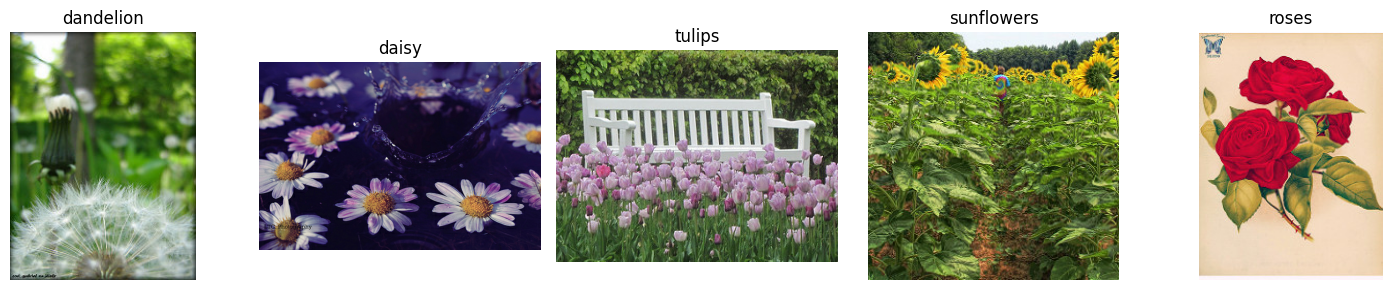

In [ ]:
fig, axes = plt.subplots(1, num_classes, figsize=(15, 3))
for c, ax in enumerate(axes):
    idx = next(i for i in train_idx if labels[i] == c)
    ax.imshow(images[idx])
    ax.set_title(class_names[c]); ax.axis("off")
plt.tight_layout(); plt.show()

In [ ]:
# ResNet50 preprocess_input expects RGB pixel values in [0,255] and converts to its ImageNet convention.
augmenter = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal", seed=SEED),
    tf.keras.layers.RandomRotation(0.05, seed=SEED),
    tf.keras.layers.RandomZoom(0.10, seed=SEED),
    tf.keras.layers.RandomTranslation(0.05, 0.05, seed=SEED),
], name="augmentation")

def decode_resize(image, label, training=False):
    image = tf.image.resize(tf.cast(image, tf.float32), IMG_SIZE)
    if training:
        image = augmenter(image, training=True)
    image = tf.keras.applications.resnet50.preprocess_input(image)
    label = tf.one_hot(tf.cast(label, tf.int32), num_classes)
    return image, label

def make_dataset(index_array, training=False):
    # Keep labels and images from the one fixed split.
    subset_images = [images[i] for i in index_array]
    subset_labels = labels[index_array]
    ds = tf.data.Dataset.from_generator(
        lambda: iter(zip(subset_images, subset_labels)),
        output_signature=(
            tf.TensorSpec(shape=(None, None, 3), dtype=tf.uint8),
            tf.TensorSpec(shape=(), dtype=tf.int64)
        )
    )
    if training:
        ds = ds.shuffle(min(len(index_array), 2000), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(lambda x, y: decode_resize(x, y, training), num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_dataset(train_idx, True)
val_ds = make_dataset(val_idx, False)
test_ds = make_dataset(test_idx, False)

In [ ]:
base = tf.keras.applications.ResNet50(
    include_top=False, weights="imagenet", input_shape=(224, 224, 3)
)
# Keras ResNet50 output layer names are stable in standard TensorFlow releases.
stage_layer_names = {
    "P2": "conv2_block3_out",
    "P3": "conv3_block4_out",
    "P4": "conv4_block6_out",
    "P5": "conv5_block3_out",
}
stage_models = {}
for pos, layer_name in stage_layer_names.items():
    stage_models[pos] = tf.keras.Model(base.input, base.get_layer(layer_name).output, name=f"resnet50_{pos}_features")
    print(pos, layer_name, stage_models[pos].output_shape)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
P2 conv2_block3_out (None, 56, 56, 256)
P3 conv3_block4_out (None, 28, 28, 512)
P4 conv4_block6_out (None, 14, 14, 1024)
P5 conv5_block3_out (None, 7, 7, 2048)


In [ ]:
def channel_attention(x, ratio=16, name="channel_attention"):
    channels = int(x.shape[-1])
    hidden = max(channels // ratio, 1)
    avg = tf.keras.layers.GlobalAveragePooling2D(keepdims=True, name=f"{name}_gap")(x)
    shared1 = tf.keras.layers.Dense(hidden, activation="relu", name=f"{name}_fc1")
    shared2 = tf.keras.layers.Dense(channels, activation="sigmoid", name=f"{name}_fc2")
    weights = shared2(shared1(avg))
    return tf.keras.layers.Multiply(name=f"{name}_multiply")([x, weights]), weights

def spatial_attention(x, kernel_size=7, name="spatial_attention"):
    avg = tf.keras.layers.Lambda(lambda z: tf.reduce_mean(z, axis=-1, keepdims=True), name=f"{name}_avg")(x)
    mx = tf.keras.layers.Lambda(lambda z: tf.reduce_max(z, axis=-1, keepdims=True), name=f"{name}_max")(x)
    merged = tf.keras.layers.Concatenate(axis=-1, name=f"{name}_concat")([avg, mx])
    weights = tf.keras.layers.Conv2D(1, kernel_size, padding="same", activation="sigmoid",
                                     use_bias=False, name=f"{name}_conv")(merged)
    return tf.keras.layers.Multiply(name=f"{name}_multiply")([x, weights]), weights

class ResidualScale(tf.keras.layers.Layer):
    def build(self, input_shape):
        self.gamma = self.add_weight(name="gamma", shape=(), initializer="zeros", trainable=True)
    def call(self, inputs):
        original, attended = inputs
        return original + self.gamma * attended

def self_attention(x, key_dim=64, name="self_attention"):
    # Used at P3/P4 only; quadratic attention over H*W locations.
    shape = tf.keras.backend.int_shape(x)
    h, w, channels = shape[1], shape[2], shape[3]
    if h is None or w is None:
        raise ValueError("Self-attention requires static spatial dimensions.")
    n = h * w
    q = tf.keras.layers.Conv2D(key_dim, 1, name=f"{name}_q")(x)
    k = tf.keras.layers.Conv2D(key_dim, 1, name=f"{name}_k")(x)
    v = tf.keras.layers.Conv2D(channels, 1, name=f"{name}_v")(x)
    q = tf.keras.layers.Reshape((n, key_dim), name=f"{name}_q_flat")(q)
    k = tf.keras.layers.Reshape((n, key_dim), name=f"{name}_k_flat")(k)
    v = tf.keras.layers.Reshape((n, channels), name=f"{name}_v_flat")(v)
    scores = tf.keras.layers.Lambda(
        lambda z: tf.matmul(z[0], z[1], transpose_b=True) / tf.sqrt(tf.cast(key_dim, tf.float32)),
        name=f"{name}_scores")([q, k])
    attn = tf.keras.layers.Softmax(axis=-1, name=f"{name}_weights")(scores)
    out = tf.keras.layers.Lambda(lambda z: tf.matmul(z[0], z[1]), name=f"{name}_apply")([attn, v])
    out = tf.keras.layers.Reshape((h, w, channels), name=f"{name}_reshape")(out)
    # Learnable residual scale, initialized to zero as in common non-local attention blocks.
    scaled = ResidualScale(name=f"{name}_residual")([x, out])
    return scaled, attn

def eca_attention(x, name="eca"):
    channels = int(x.shape[-1])
    descriptor = tf.keras.layers.GlobalAveragePooling2D(keepdims=True, name=f"{name}_gap")(x)
    # Conv1D across channel axis implements efficient local channel interaction.
    descriptor = tf.keras.layers.Reshape((channels, 1), name=f"{name}_reshape1d")(descriptor)
    weights = tf.keras.layers.Conv1D(1, 3, padding="same", use_bias=False, name=f"{name}_conv1d")(descriptor)
    weights = tf.keras.layers.Activation("sigmoid", name=f"{name}_sigmoid")(weights)
    weights = tf.keras.layers.Reshape((1, 1, channels), name=f"{name}_reshape4d")(weights)
    return tf.keras.layers.Multiply(name=f"{name}_multiply")([x, weights]), weights

def se_attention(x, ratio=16, name="se"):
    return channel_attention(x, ratio=ratio, name=name)

def cbam_attention(x, ratio=16, kernel_size=7, order="channel_spatial", name="cbam"):
    if order == "channel_spatial":
        x, cw = channel_attention(x, ratio, f"{name}_channel")
        x, sw = spatial_attention(x, kernel_size, f"{name}_spatial")
    else:
        x, sw = spatial_attention(x, kernel_size, f"{name}_spatial")
        x, cw = channel_attention(x, ratio, f"{name}_channel")
    return x, {"channel": cw, "spatial": sw}

def apply_attention(x, kind, ratio=16, kernel_size=7, order="channel_spatial", name="attn"):
    if kind == "none": return x, None
    if kind == "channel": return channel_attention(x, ratio, name)
    if kind == "spatial": return spatial_attention(x, kernel_size, name)
    if kind == "channel_spatial": return cbam_attention(x, ratio, kernel_size, order, name)
    if kind == "self": return self_attention(x, name=name)
    if kind == "SE": return se_attention(x, ratio, name)
    if kind == "ECA": return eca_attention(x, name)
    if kind == "CBAM": return cbam_attention(x, ratio, kernel_size, order, name)
    raise ValueError(f"Unknown attention kind: {kind}")

In [ ]:
history_store = {}
result_rows = []
model_store = {}
head_store = {}
attention_tensors = {}

def build_model(position="P3", attention="none", ratio=16, kernel_size=7, order="channel_spatial",
                dropout=0.3, fine_tune=False):
    extractor = stage_models[position]
    extractor.trainable = bool(fine_tune)
    inputs = tf.keras.Input(shape=(224, 224, 3), name="image")
    features = extractor(inputs, training=False)
    feature_input = tf.keras.Input(shape=extractor.output_shape[1:], name=f"{position}_feature_input")
    refined, maps = apply_attention(feature_input, attention, ratio, kernel_size, order,
                                    name=f"{attention}_{position}")
    pooled = tf.keras.layers.GlobalAveragePooling2D(name="gap")(refined)
    x = tf.keras.layers.Dropout(dropout, seed=SEED, name="dropout")(pooled)
    outputs = tf.keras.layers.Dense(num_classes, activation="softmax", name="flower_classifier")(x)
    head = tf.keras.Model(feature_input, outputs, name=f"{position}_{attention}_head")
    model_outputs = head(features)
    model = tf.keras.Model(inputs, model_outputs, name=f"ResNet50_{position}_{attention}")
    return model, maps, head

def count_params(model):
    return int(model.count_params()), int(np.sum([tf.keras.backend.count_params(w) for w in model.trainable_weights]))

def plot_history(history, title):
    h = history.history
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(h.get("accuracy", []), label="train accuracy")
    ax[0].plot(h.get("val_accuracy", []), label="validation accuracy")
    ax[0].set_title(f"{title}: accuracy"); ax[0].set_xlabel("Epoch"); ax[0].legend(); ax[0].grid(True, alpha=.3)
    ax[1].plot(h.get("loss", []), label="train loss")
    ax[1].plot(h.get("val_loss", []), label="validation loss")
    ax[1].set_title(f"{title}: loss"); ax[1].set_xlabel("Epoch"); ax[1].legend(); ax[1].grid(True, alpha=.3)
    plt.tight_layout(); plt.show()

def fit_experiment(name, position="P3", attention="none", ratio=16, kernel_size=7,
                   order="channel_spatial", dropout=0.3, lr=1e-3, epochs=5, fine_tune=False):
    tf.keras.backend.clear_session()
    model, maps, head = build_model(position, attention, ratio, kernel_size, order, dropout, fine_tune)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
                  loss="categorical_crossentropy", metrics=["accuracy"])
    callbacks = [
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=1, min_lr=1e-6)
    ]
    start = time.perf_counter()
    hist = model.fit(train_ds, validation_data=val_ds, epochs=epochs, callbacks=callbacks, verbose=1)
    train_seconds = time.perf_counter() - start
    y_true, y_pred, infer_time = predict_model(model, test_ds)
    total, trainable = count_params(model)
    row = {
        "Model": name, "Position": position if attention != "none" else "–",
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "F1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "Trainable Parameters": trainable, "Parameters": total,
        "Inference Time (ms/image)": infer_time * 1000,
        "Training Time (s)": train_seconds,
        "y_true": y_true, "y_pred": y_pred
    }
    result_rows.append(row); history_store[name] = hist; model_store[name] = model
    head_store[name] = head
    attention_tensors[name] = maps
    plot_history(hist, name)
    print(pd.DataFrame([{k: row[k] for k in ["Model","Position","Accuracy","Precision","Recall","F1","Trainable Parameters","Parameters","Inference Time (ms/image)"]}]).to_string(index=False))
    return model, hist, row

def predict_model(model, dataset):
    y_true, y_pred = [], []
    # Warm-up one batch to reduce one-time tracing overhead.
    for xb, yb in dataset.take(1):
        _ = model(xb, training=False)
    start = time.perf_counter()
    n_images = 0
    for xb, yb in dataset:
        probs = model(xb, training=False).numpy()
        y_pred.extend(np.argmax(probs, axis=1).tolist())
        y_true.extend(np.argmax(yb.numpy(), axis=1).tolist())
        n_images += xb.shape[0]
    elapsed = time.perf_counter() - start
    return np.asarray(y_true), np.asarray(y_pred), elapsed / max(n_images, 1)

def current_results():
    if not result_rows:
        return pd.DataFrame()
    cols = ["Model","Position","Accuracy","Precision","Recall","F1","Trainable Parameters","Parameters","Inference Time (ms/image)","Training Time (s)"]
    df = pd.DataFrame([{c:r[c] for c in cols} for r in result_rows])
    return df

Epoch 1/5
      5/Unknown 9s 37ms/step - accuracy: 0.2679 - loss: 1.9017

I0000 00:00:1792422276.884396     819 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


    161/Unknown 29s 130ms/step - accuracy: 0.2988 - loss: 1.7357

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


161/161 ━━━━━━━━━━━━━━━━━━━━ 34s 157ms/step - accuracy: 0.3710 - loss: 1.5324 - val_accuracy: 0.6800 - val_loss: 0.9780 - learning_rate: 0.0010
Epoch 2/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 20s 121ms/step - accuracy: 0.5598 - loss: 1.1087 - val_accuracy: 0.6818 - val_loss: 0.8709 - learning_rate: 0.0010
Epoch 3/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 20s 123ms/step - accuracy: 0.6251 - loss: 0.9685 - val_accuracy: 0.7364 - val_loss: 0.7501 - learning_rate: 0.0010
Epoch 4/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 21s 129ms/step - accuracy: 0.6524 - loss: 0.9079 - val_accuracy: 0.7509 - val_loss: 0.7388 - learning_rate: 0.0010
Epoch 5/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 21s 127ms/step - accuracy: 0.6684 - loss: 0.8733 - val_accuracy: 0.7400 - val_loss: 0.7147 - learning_rate: 0.0010


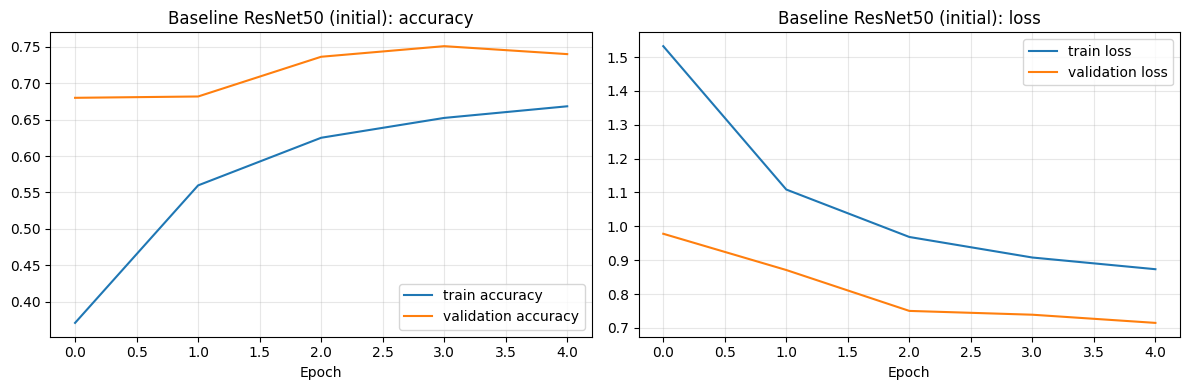

                      Model Position  Accuracy  Precision   Recall       F1  Trainable Parameters  Parameters  Inference Time (ms/image)
Baseline ResNet50 (initial)        –  0.733212   0.771413 0.739245 0.737666                  2565     1462661                   8.843187


In [ ]:
# Initial baseline with reasonable starting hyperparameters.
# This is a reference run; the tuned baseline will be trained after the search below.
INITIAL_BASELINE_EPOCHS = 5
initial_baseline_model, initial_baseline_history, initial_baseline_row = fit_experiment(
    "Baseline ResNet50 (initial)", position="P3", attention="none",
    dropout=0.3, lr=1e-3, epochs=INITIAL_BASELINE_EPOCHS
)

\nBaseline tuning trial 1/5: {'lr': 0.001, 'dropout': 0.3}
Epoch 1/3
    161/Unknown 28s 134ms/step - accuracy: 0.2831 - loss: 1.8211

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


161/161 ━━━━━━━━━━━━━━━━━━━━ 32s 161ms/step - accuracy: 0.3593 - loss: 1.5776 - val_accuracy: 0.6000 - val_loss: 1.0661
Epoch 2/3
161/161 ━━━━━━━━━━━━━━━━━━━━ 21s 129ms/step - accuracy: 0.5321 - loss: 1.1690 - val_accuracy: 0.7036 - val_loss: 0.8385
Epoch 3/3
161/161 ━━━━━━━━━━━━━━━━━━━━ 20s 121ms/step - accuracy: 0.6057 - loss: 1.0105 - val_accuracy: 0.7600 - val_loss: 0.7633
\nBaseline tuning trial 2/5: {'lr': 0.0003, 'dropout': 0.3}
Epoch 1/3
161/161 ━━━━━━━━━━━━━━━━━━━━ 31s 155ms/step - accuracy: 0.2705 - loss: 1.7532 - val_accuracy: 0.4873 - val_loss: 1.3148
Epoch 2/3
161/161 ━━━━━━━━━━━━━━━━━━━━ 20s 123ms/step - accuracy: 0.3819 - loss: 1.4797 - val_accuracy: 0.5618 - val_loss: 1.1319
Epoch 3/3
161/161 ━━━━━━━━━━━━━━━━━━━━ 21s 124ms/step - accuracy: 0.4609 - loss: 1.3388 - val_accuracy: 0.6164 - val_loss: 1.0262
\nBaseline tuning trial 3/5: {'lr': 0.0001, 'dropout': 0.3}
Epoch 1/3
161/161 ━━━━━━━━━━━━━━━━━━━━ 31s 156ms/step - accuracy: 0.2297 - loss: 1.9383 - val_accuracy: 0.2836

,lr,dropout,best_val_accuracy,val_loss_at_best_accuracy,best_epoch
0,0.0010,0.3,0.760000,0.763291,3
1,0.0003,0.5,0.634545,1.072289,3
2,0.0003,0.3,0.616364,1.026215,3
3,0.0001,0.3,0.483636,1.350724,3
4,0.0001,0.5,0.456364,1.379582,3


Selected baseline hyperparameters: {'learning_rate': 0.001, 'dropout': 0.3, 'attention_reduction_ratio_fixed': 16, 'spatial_kernel_fixed': 7}
Epoch 1/5
    161/Unknown 26s 128ms/step - accuracy: 0.2551 - loss: 1.8295

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


161/161 ━━━━━━━━━━━━━━━━━━━━ 31s 154ms/step - accuracy: 0.3379 - loss: 1.6120 - val_accuracy: 0.6364 - val_loss: 1.0209 - learning_rate: 0.0010
Epoch 2/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 21s 124ms/step - accuracy: 0.5543 - loss: 1.1579 - val_accuracy: 0.7127 - val_loss: 0.8610 - learning_rate: 0.0010
Epoch 3/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 20s 123ms/step - accuracy: 0.6092 - loss: 0.9954 - val_accuracy: 0.7655 - val_loss: 0.7406 - learning_rate: 0.0010
Epoch 4/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 20s 122ms/step - accuracy: 0.6434 - loss: 0.9095 - val_accuracy: 0.7491 - val_loss: 0.7343 - learning_rate: 0.0010
Epoch 5/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 20s 122ms/step - accuracy: 0.6652 - loss: 0.8811 - val_accuracy: 0.7582 - val_loss: 0.6973 - learning_rate: 0.0010


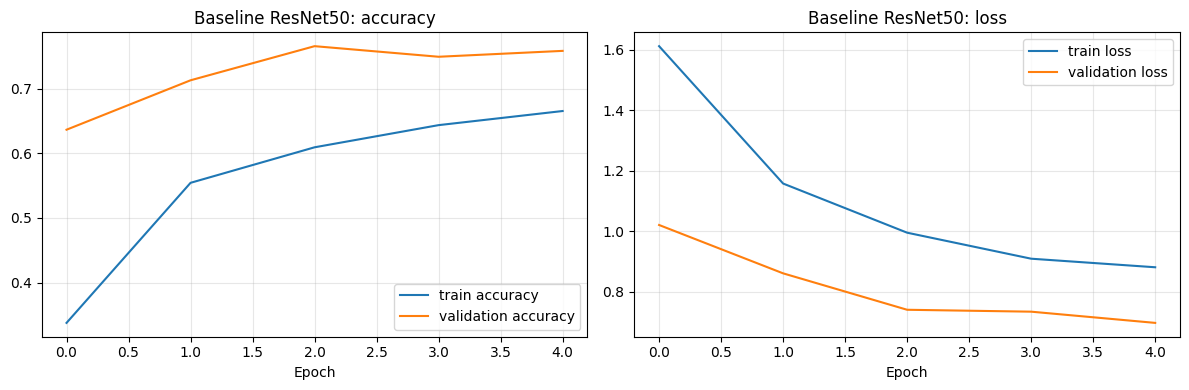

            Model Position  Accuracy  Precision   Recall       F1  Trainable Parameters  Parameters  Inference Time (ms/image)
Baseline ResNet50        –  0.729583   0.753564 0.733006 0.730788                  2565     1462661                   7.809387


In [ ]:
# Compact validation-only search on the no-attention baseline.
# Increase TUNE_EPOCHS (e.g., 5–8) and add configurations if compute allows.
TUNE_EPOCHS = 3
tuning_rows = []
tuning_configs = [
    {"lr": 1e-3, "dropout": 0.3},
    {"lr": 3e-4, "dropout": 0.3},
    {"lr": 1e-4, "dropout": 0.3},
    {"lr": 3e-4, "dropout": 0.5},
    {"lr": 1e-4, "dropout": 0.5},
]

for i, cfg in enumerate(tuning_configs, 1):
    print(f"\\nBaseline tuning trial {i}/{len(tuning_configs)}: {cfg}")
    tf.keras.backend.clear_session()
    model, maps, head = build_model(
        position="P3", attention="none", dropout=cfg["dropout"]
    )
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=cfg["lr"]),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    h = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=TUNE_EPOCHS,
        callbacks=[
            tf.keras.callbacks.EarlyStopping(
                monitor="val_loss", patience=1, restore_best_weights=True
            )
        ],
        verbose=1
    )
    best_epoch = int(np.argmax(h.history["val_accuracy"]))
    tuning_rows.append({
        **cfg,
        "best_val_accuracy": float(max(h.history["val_accuracy"])),
        "val_loss_at_best_accuracy": float(h.history["val_loss"][best_epoch]),
        "best_epoch": best_epoch + 1
    })
    del model, head
    gc.collect()

tuning_df = pd.DataFrame(tuning_rows).sort_values(
    ["best_val_accuracy", "val_loss_at_best_accuracy"],
    ascending=[False, True]
).reset_index(drop=True)
display(tuning_df)

best_cfg = tuning_df.iloc[0]
BEST_LR = float(best_cfg["lr"])
BEST_DROPOUT = float(best_cfg["dropout"])

# These are attention-specific settings, not baseline-tuned hyperparameters.
# Keep them fixed across attention comparisons unless running a separate ablation.
BEST_RATIO = 16
BEST_KERNEL = 7

print("Selected baseline hyperparameters:", {
    "learning_rate": BEST_LR,
    "dropout": BEST_DROPOUT,
    "attention_reduction_ratio_fixed": BEST_RATIO,
    "spatial_kernel_fixed": BEST_KERNEL
})

# Train the final baseline using the selected hyperparameters.
# This is the baseline result to compare with the attention variants.
BASELINE_EPOCHS = 5
baseline_model, baseline_history, baseline_row = fit_experiment(
    "Baseline ResNet50", position="P3", attention="none",
    dropout=BEST_DROPOUT, lr=BEST_LR, epochs=BASELINE_EPOCHS
)


Epoch 1/5
    161/Unknown 28s 130ms/step - accuracy: 0.3608 - loss: 1.4868

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


161/161 ━━━━━━━━━━━━━━━━━━━━ 32s 158ms/step - accuracy: 0.4866 - loss: 1.2419 - val_accuracy: 0.6927 - val_loss: 0.8132 - learning_rate: 0.0010
Epoch 2/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 21s 125ms/step - accuracy: 0.6777 - loss: 0.8397 - val_accuracy: 0.6364 - val_loss: 0.8823 - learning_rate: 0.0010
Epoch 3/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 21s 126ms/step - accuracy: 0.7151 - loss: 0.7381 - val_accuracy: 0.7200 - val_loss: 0.6753 - learning_rate: 3.0000e-04
Epoch 4/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 20s 121ms/step - accuracy: 0.7450 - loss: 0.6932 - val_accuracy: 0.7745 - val_loss: 0.6267 - learning_rate: 3.0000e-04
Epoch 5/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 20s 123ms/step - accuracy: 0.7415 - loss: 0.6884 - val_accuracy: 0.7655 - val_loss: 0.6000 - learning_rate: 3.0000e-04


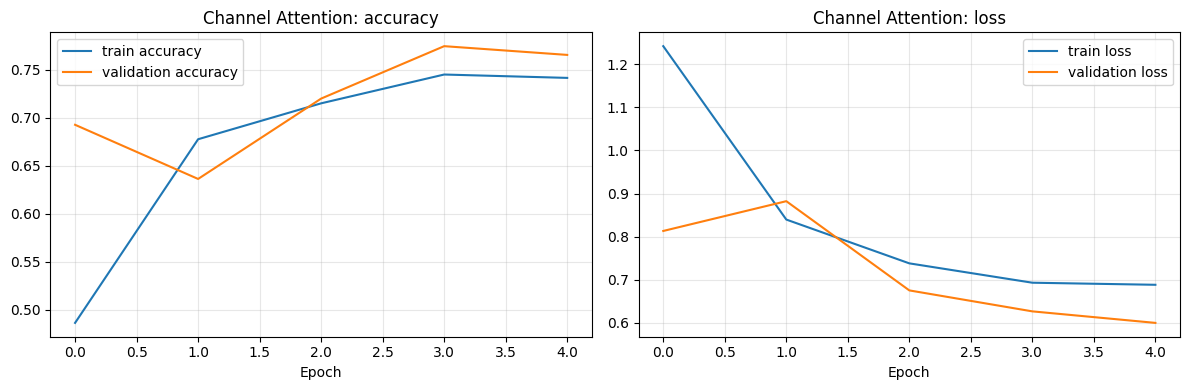

            Model Position  Accuracy  Precision   Recall       F1  Trainable Parameters  Parameters  Inference Time (ms/image)
Channel Attention       P3  0.760436   0.774721 0.753875 0.756732                 35877     1495973                   8.478753
Epoch 1/5
    161/Unknown 29s 138ms/step - accuracy: 0.2589 - loss: 1.5873

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


161/161 ━━━━━━━━━━━━━━━━━━━━ 34s 169ms/step - accuracy: 0.3126 - loss: 1.5237 - val_accuracy: 0.5618 - val_loss: 1.1690 - learning_rate: 0.0010
Epoch 2/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 21s 129ms/step - accuracy: 0.5707 - loss: 1.1113 - val_accuracy: 0.7309 - val_loss: 0.7654 - learning_rate: 0.0010
Epoch 3/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 20s 123ms/step - accuracy: 0.6446 - loss: 0.9351 - val_accuracy: 0.6800 - val_loss: 0.7969 - learning_rate: 0.0010
Epoch 4/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 20s 123ms/step - accuracy: 0.6808 - loss: 0.8764 - val_accuracy: 0.7364 - val_loss: 0.6995 - learning_rate: 3.0000e-04
Epoch 5/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 20s 122ms/step - accuracy: 0.6808 - loss: 0.8485 - val_accuracy: 0.7418 - val_loss: 0.6974 - learning_rate: 3.0000e-04


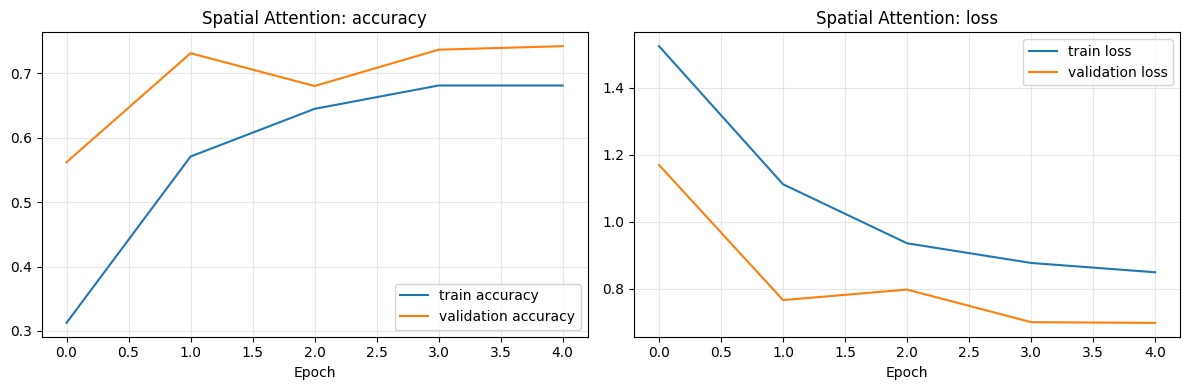

            Model Position  Accuracy  Precision   Recall       F1  Trainable Parameters  Parameters  Inference Time (ms/image)
Spatial Attention       P3  0.725953   0.743452 0.729739 0.725807                  2663     1462759                   7.885384
Epoch 1/5
    161/Unknown 29s 133ms/step - accuracy: 0.3385 - loss: 1.5162

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


161/161 ━━━━━━━━━━━━━━━━━━━━ 34s 162ms/step - accuracy: 0.4558 - loss: 1.3102 - val_accuracy: 0.6873 - val_loss: 0.8884 - learning_rate: 0.0010
Epoch 2/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 20s 124ms/step - accuracy: 0.6672 - loss: 0.8685 - val_accuracy: 0.7109 - val_loss: 0.7484 - learning_rate: 0.0010
Epoch 3/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 20s 122ms/step - accuracy: 0.7088 - loss: 0.7498 - val_accuracy: 0.7655 - val_loss: 0.6273 - learning_rate: 0.0010
Epoch 4/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 20s 122ms/step - accuracy: 0.7485 - loss: 0.6760 - val_accuracy: 0.7236 - val_loss: 0.7576 - learning_rate: 0.0010
Epoch 5/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 20s 124ms/step - accuracy: 0.7653 - loss: 0.6362 - val_accuracy: 0.7673 - val_loss: 0.6238 - learning_rate: 3.0000e-04


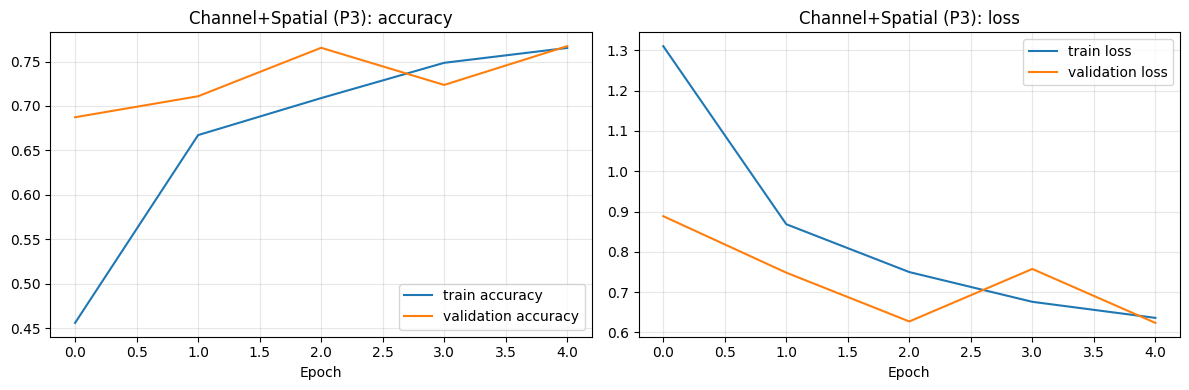

               Model Position  Accuracy  Precision   Recall       F1  Trainable Parameters  Parameters  Inference Time (ms/image)
Channel+Spatial (P3)       P3  0.742287   0.767456 0.740289 0.736844                 35975     1496071                   8.112818
Epoch 1/5
    161/Unknown 33s 152ms/step - accuracy: 0.3617 - loss: 1.6043

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


161/161 ━━━━━━━━━━━━━━━━━━━━ 39s 184ms/step - accuracy: 0.5212 - loss: 1.2210 - val_accuracy: 0.6855 - val_loss: 0.8402 - learning_rate: 0.0010
Epoch 2/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 23s 139ms/step - accuracy: 0.7256 - loss: 0.7318 - val_accuracy: 0.7727 - val_loss: 0.6271 - learning_rate: 0.0010
Epoch 3/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 23s 137ms/step - accuracy: 0.7781 - loss: 0.5980 - val_accuracy: 0.8309 - val_loss: 0.4851 - learning_rate: 0.0010
Epoch 4/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 23s 139ms/step - accuracy: 0.8046 - loss: 0.5299 - val_accuracy: 0.7982 - val_loss: 0.5216 - learning_rate: 0.0010
Epoch 5/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 23s 138ms/step - accuracy: 0.8412 - loss: 0.4205 - val_accuracy: 0.8509 - val_loss: 0.3917 - learning_rate: 3.0000e-04


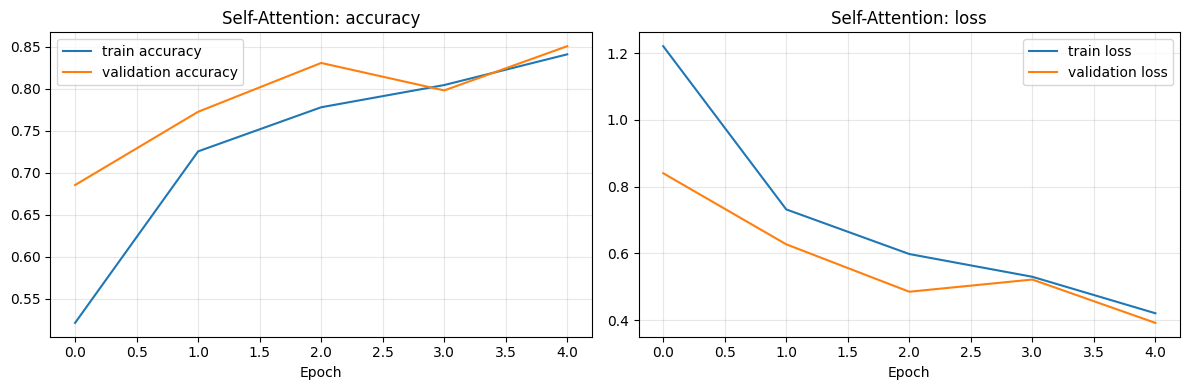

         Model Position  Accuracy  Precision   Recall       F1  Trainable Parameters  Parameters  Inference Time (ms/image)
Self-Attention       P3   0.84755   0.852103 0.854814 0.848793                330886     1790982                   8.503581
Epoch 1/5
    161/Unknown 29s 135ms/step - accuracy: 0.3813 - loss: 1.4260

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


161/161 ━━━━━━━━━━━━━━━━━━━━ 34s 165ms/step - accuracy: 0.4881 - loss: 1.2413 - val_accuracy: 0.6418 - val_loss: 0.8917 - learning_rate: 0.0010
Epoch 2/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 21s 127ms/step - accuracy: 0.6703 - loss: 0.8639 - val_accuracy: 0.7418 - val_loss: 0.6765 - learning_rate: 0.0010
Epoch 3/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 20s 123ms/step - accuracy: 0.7120 - loss: 0.7569 - val_accuracy: 0.7800 - val_loss: 0.6220 - learning_rate: 0.0010
Epoch 4/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 20s 124ms/step - accuracy: 0.7462 - loss: 0.6907 - val_accuracy: 0.7709 - val_loss: 0.6156 - learning_rate: 0.0010
Epoch 5/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 20s 123ms/step - accuracy: 0.7626 - loss: 0.6449 - val_accuracy: 0.7982 - val_loss: 0.5980 - learning_rate: 0.0010


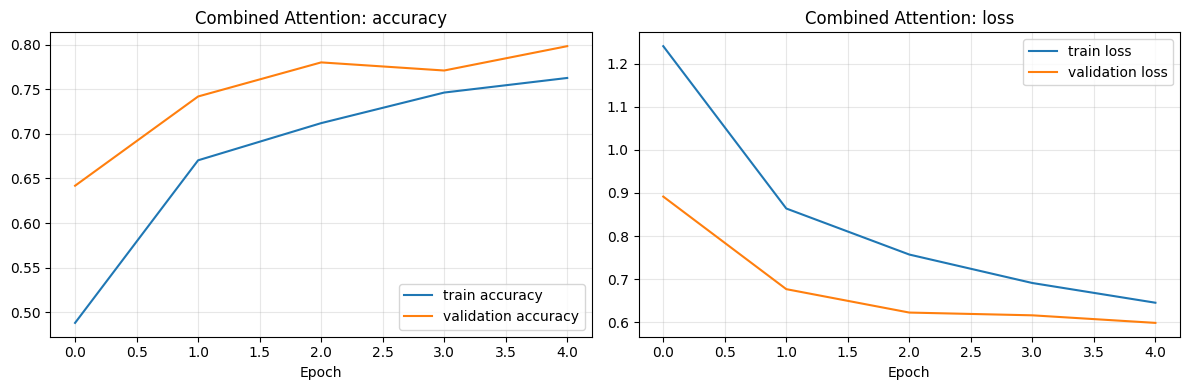

             Model Position  Accuracy  Precision   Recall       F1  Trainable Parameters  Parameters  Inference Time (ms/image)
Combined Attention       P3  0.764065   0.791161 0.771483 0.763278                 35975     1496071                   8.256509


,Model,Position,Accuracy,Precision,Recall,F1,Trainable Parameters,Parameters,Inference Time (ms/image),Training Time (s)
0,Baseline ResNet50 (initial),–,0.733212,0.771413,0.739245,0.737666,2565,1462661,8.843187,116.907732
1,Baseline ResNet50,–,0.729583,0.753564,0.733006,0.730788,2565,1462661,7.809387,112.190814
2,Channel Attention,P3,0.760436,0.774721,0.753875,0.756732,35877,1495973,8.478753,114.501728
3,Spatial Attention,P3,0.725953,0.743452,0.729739,0.725807,2663,1462759,7.885384,116.567458
4,Channel+Spatial (P3),P3,0.742287,0.767456,0.740289,0.736844,35975,1496071,8.112818,115.237224
5,Self-Attention,P3,0.847550,0.852103,0.854814,0.848793,330886,1790982,8.503581,129.768105
6,Combined Attention,P3,0.764065,0.791161,0.771483,0.763278,35975,1496071,8.256509,116.581774


In [ ]:
MAIN_EPOCHS = 5
# The tuned baseline has already been trained above. Run each attention model sequentially so its metrics/plots appear immediately.
channel_model, _, _ = fit_experiment("Channel Attention", "P3", "channel",
                                     BEST_RATIO, BEST_KERNEL, dropout=BEST_DROPOUT, lr=BEST_LR, epochs=MAIN_EPOCHS)
spatial_model, _, _ = fit_experiment("Spatial Attention", "P3", "spatial",
                                     BEST_RATIO, BEST_KERNEL, dropout=BEST_DROPOUT, lr=BEST_LR, epochs=MAIN_EPOCHS)
cs_p3_model, _, _ = fit_experiment("Channel+Spatial (P3)", "P3", "channel_spatial",
                                   BEST_RATIO, BEST_KERNEL, dropout=BEST_DROPOUT, lr=BEST_LR, epochs=MAIN_EPOCHS)
self_model, _, _ = fit_experiment("Self-Attention", "P3", "self",
                                  BEST_RATIO, BEST_KERNEL, dropout=BEST_DROPOUT, lr=BEST_LR, epochs=MAIN_EPOCHS)
combined_model, _, _ = fit_experiment("Combined Attention", "P3", "channel_spatial",
                                      BEST_RATIO, BEST_KERNEL, dropout=BEST_DROPOUT, lr=BEST_LR, epochs=MAIN_EPOCHS)
display(current_results())

P2 feature shape: (None, 56, 56, 256)
P3 feature shape: (None, 28, 28, 512)
P4 feature shape: (None, 14, 14, 1024)
Epoch 1/5
    161/Unknown 25s 120ms/step - accuracy: 0.2167 - loss: 1.6067

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


161/161 ━━━━━━━━━━━━━━━━━━━━ 28s 141ms/step - accuracy: 0.2678 - loss: 1.5630 - val_accuracy: 0.4600 - val_loss: 1.3332 - learning_rate: 0.0010
Epoch 2/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 18s 111ms/step - accuracy: 0.4877 - loss: 1.2607 - val_accuracy: 0.5727 - val_loss: 1.1211 - learning_rate: 0.0010
Epoch 3/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 18s 111ms/step - accuracy: 0.5282 - loss: 1.1560 - val_accuracy: 0.5764 - val_loss: 1.0838 - learning_rate: 0.0010
Epoch 4/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 18s 111ms/step - accuracy: 0.5812 - loss: 1.0868 - val_accuracy: 0.5964 - val_loss: 1.0277 - learning_rate: 0.0010
Epoch 5/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 19s 112ms/step - accuracy: 0.6057 - loss: 1.0234 - val_accuracy: 0.5945 - val_loss: 1.0650 - learning_rate: 0.0010


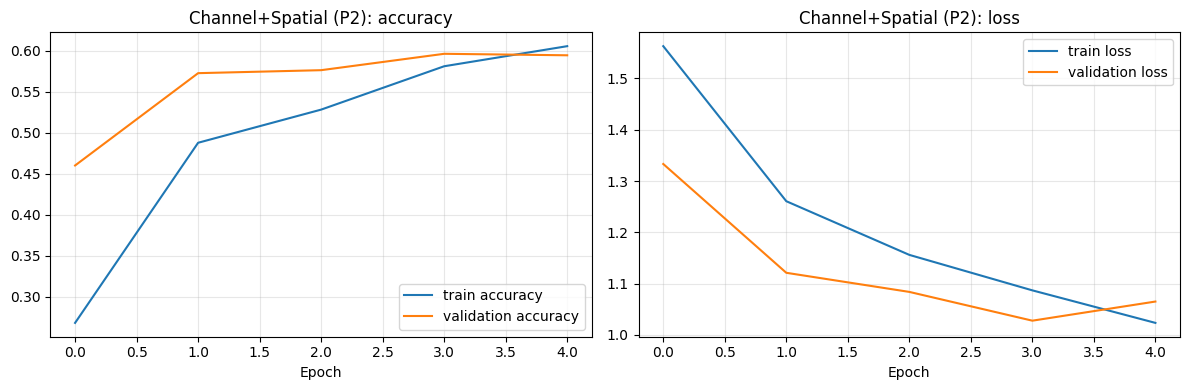

               Model Position  Accuracy  Precision  Recall       F1  Trainable Parameters  Parameters  Inference Time (ms/image)
Channel+Spatial (P2)       P2  0.577132   0.629724  0.5623 0.533742                  9847      239607                   4.769399
Epoch 1/5
    161/Unknown 35s 153ms/step - accuracy: 0.4967 - loss: 1.2336

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


161/161 ━━━━━━━━━━━━━━━━━━━━ 43s 199ms/step - accuracy: 0.6629 - loss: 0.9168 - val_accuracy: 0.8582 - val_loss: 0.4294 - learning_rate: 0.0010
Epoch 2/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 23s 140ms/step - accuracy: 0.8307 - loss: 0.4832 - val_accuracy: 0.8727 - val_loss: 0.3233 - learning_rate: 0.0010
Epoch 3/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 23s 140ms/step - accuracy: 0.8560 - loss: 0.3919 - val_accuracy: 0.8745 - val_loss: 0.3200 - learning_rate: 0.0010
Epoch 4/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 23s 140ms/step - accuracy: 0.8595 - loss: 0.3794 - val_accuracy: 0.8909 - val_loss: 0.2972 - learning_rate: 0.0010
Epoch 5/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 23s 139ms/step - accuracy: 0.8817 - loss: 0.3326 - val_accuracy: 0.8891 - val_loss: 0.3211 - learning_rate: 0.0010


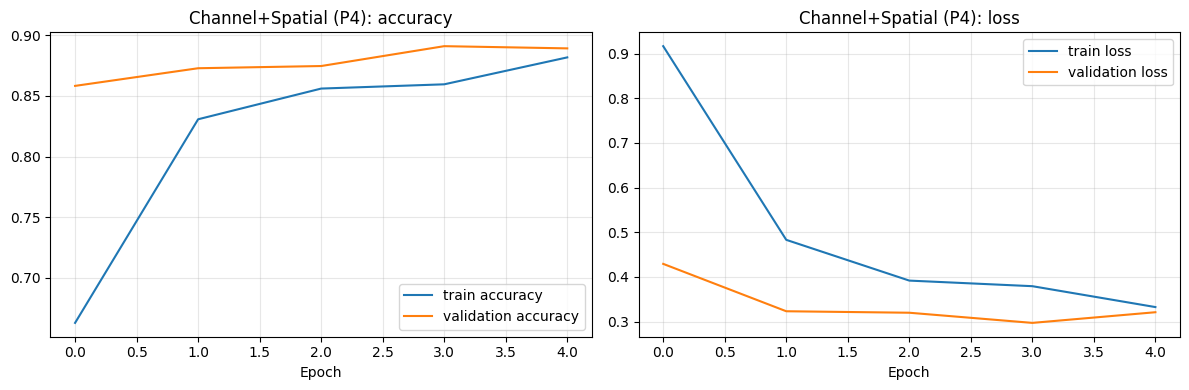

               Model Position  Accuracy  Precision   Recall       F1  Trainable Parameters  Parameters  Inference Time (ms/image)
Channel+Spatial (P4)       P4  0.891107   0.891144 0.895472 0.890689                137383     8726567                  13.447957


,Model,Position,Accuracy,Precision,Recall,F1,Trainable Parameters,Parameters,Inference Time (ms/image),Training Time (s)
0,Baseline ResNet50 (initial),–,0.733212,0.771413,0.739245,0.737666,2565,1462661,8.843187,116.907732
1,Baseline ResNet50,–,0.729583,0.753564,0.733006,0.730788,2565,1462661,7.809387,112.190814
2,Channel Attention,P3,0.760436,0.774721,0.753875,0.756732,35877,1495973,8.478753,114.501728
3,Spatial Attention,P3,0.725953,0.743452,0.729739,0.725807,2663,1462759,7.885384,116.567458
4,Channel+Spatial (P3),P3,0.742287,0.767456,0.740289,0.736844,35975,1496071,8.112818,115.237224
5,Self-Attention,P3,0.847550,0.852103,0.854814,0.848793,330886,1790982,8.503581,129.768105
6,Combined Attention,P3,0.764065,0.791161,0.771483,0.763278,35975,1496071,8.256509,116.581774
7,Channel+Spatial (P2),P2,0.577132,0.629724,0.562300,0.533742,9847,239607,4.769399,102.349621
8,Channel+Spatial (P4),P4,0.891107,0.891144,0.895472,0.890689,137383,8726567,13.447957,135.269605


In [ ]:
for pos in ["P2", "P3", "P4"]:
    print(pos, "feature shape:", stage_models[pos].output_shape)
cs_p2_model, _, _ = fit_experiment("Channel+Spatial (P2)", "P2", "channel_spatial",
                                   BEST_RATIO, BEST_KERNEL, dropout=BEST_DROPOUT, lr=BEST_LR, epochs=MAIN_EPOCHS)
# P3 already trained in the prior experiment; do not retrain it merely to fill the position table.
cs_p4_model, _, _ = fit_experiment("Channel+Spatial (P4)", "P4", "channel_spatial",
                                   BEST_RATIO, BEST_KERNEL, dropout=BEST_DROPOUT, lr=BEST_LR, epochs=MAIN_EPOCHS)
display(current_results())

Epoch 1/5
    161/Unknown 42s 162ms/step - accuracy: 0.5217 - loss: 1.1910

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


161/161 ━━━━━━━━━━━━━━━━━━━━ 51s 219ms/step - accuracy: 0.6563 - loss: 0.8969 - val_accuracy: 0.7982 - val_loss: 0.5471
Epoch 2/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 23s 141ms/step - accuracy: 0.8100 - loss: 0.5140 - val_accuracy: 0.8727 - val_loss: 0.3530
Epoch 3/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 23s 139ms/step - accuracy: 0.8497 - loss: 0.4146 - val_accuracy: 0.8982 - val_loss: 0.2888
Epoch 4/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 23s 139ms/step - accuracy: 0.8762 - loss: 0.3571 - val_accuracy: 0.8945 - val_loss: 0.2882
Epoch 5/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 23s 139ms/step - accuracy: 0.8840 - loss: 0.3251 - val_accuracy: 0.9018 - val_loss: 0.3003


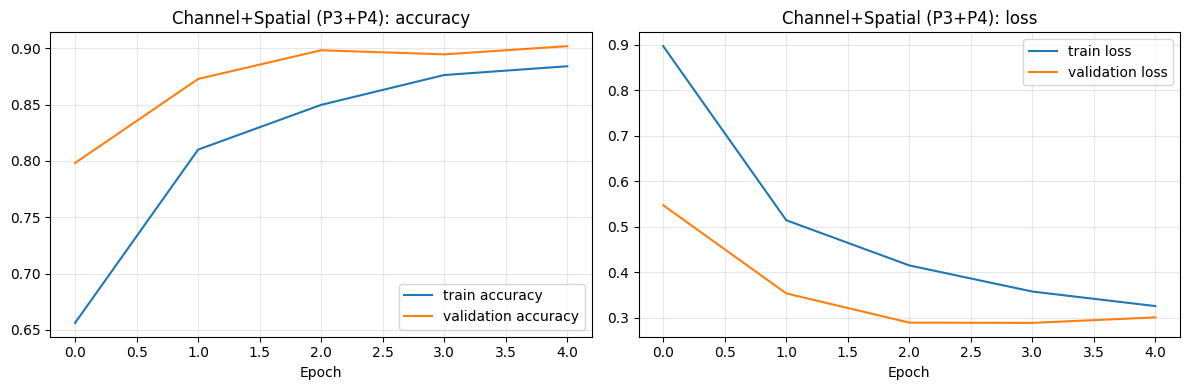

,Model,Position,Accuracy,Precision,Recall,F1,Trainable Parameters,Parameters,Inference Time (ms/image),Training Time (s)
0,Baseline ResNet50 (initial),–,0.733212,0.771413,0.739245,0.737666,2565,1462661,8.843187,116.907732
1,Baseline ResNet50,–,0.729583,0.753564,0.733006,0.730788,2565,1462661,7.809387,112.190814
2,Channel Attention,P3,0.760436,0.774721,0.753875,0.756732,35877,1495973,8.478753,114.501728
3,Spatial Attention,P3,0.725953,0.743452,0.729739,0.725807,2663,1462759,7.885384,116.567458
4,Channel+Spatial (P3),P3,0.742287,0.767456,0.740289,0.736844,35975,1496071,8.112818,115.237224
5,Self-Attention,P3,0.847550,0.852103,0.854814,0.848793,330886,1790982,8.503581,129.768105
6,Combined Attention,P3,0.764065,0.791161,0.771483,0.763278,35975,1496071,8.256509,116.581774
7,Channel+Spatial (P2),P2,0.577132,0.629724,0.562300,0.533742,9847,239607,4.769399,102.349621
8,Channel+Spatial (P4),P4,0.891107,0.891144,0.895472,0.890689,137383,8726567,13.447957,135.269605
9,Channel+Spatial (P3+P4),P3+P4,0.896552,0.897024,0.903404,0.897282,173353,8762537,20.303888,142.867480


In [ ]:
def build_multistage_model(dropout=BEST_DROPOUT, ratio=BEST_RATIO, kernel_size=BEST_KERNEL):
    inp = tf.keras.Input(shape=(224,224,3))
    features = []
    for pos in ["P3", "P4"]:
        z = stage_models[pos](inp, training=False)
        z, _ = cbam_attention(z, ratio, kernel_size, name=f"multi_{pos}")
        features.append(tf.keras.layers.GlobalAveragePooling2D()(z))
    z = tf.keras.layers.Concatenate()(features)
    z = tf.keras.layers.Dropout(dropout)(z)
    out = tf.keras.layers.Dense(num_classes, activation="softmax")(z)
    return tf.keras.Model(inp, out, name="ResNet50_P3_P4_multistage")

def fit_multistage(name, epochs=MAIN_EPOCHS):
    model = build_multistage_model()
    model.compile(optimizer=tf.keras.optimizers.Adam(BEST_LR), loss="categorical_crossentropy", metrics=["accuracy"])
    start = time.perf_counter()
    hist = model.fit(train_ds, validation_data=val_ds, epochs=epochs,
                     callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)],
                     verbose=1)
    train_seconds = time.perf_counter()-start
    yt, yp, inf = predict_model(model, test_ds)
    total, trainable = count_params(model)
    row = {"Model":name,"Position":"P3+P4","Accuracy":accuracy_score(yt,yp),
           "Precision":precision_score(yt,yp,average="macro",zero_division=0),
           "Recall":recall_score(yt,yp,average="macro",zero_division=0),
           "F1":f1_score(yt,yp,average="macro",zero_division=0),
           "Trainable Parameters":trainable,"Parameters":total,
           "Inference Time (ms/image)":inf*1000,"Training Time (s)":train_seconds,
           "y_true":yt,"y_pred":yp}
    result_rows.append(row); history_store[name]=hist; model_store[name]=model
    plot_history(hist,name)
    return model,row
multistage_model, multistage_row = fit_multistage("Channel+Spatial (P3+P4)")
display(current_results())

Epoch 1/5
    161/Unknown 29s 133ms/step - accuracy: 0.2757 - loss: 1.5408

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


161/161 ━━━━━━━━━━━━━━━━━━━━ 34s 163ms/step - accuracy: 0.4017 - loss: 1.3600 - val_accuracy: 0.6818 - val_loss: 0.8860 - learning_rate: 0.0010
Epoch 2/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 21s 124ms/step - accuracy: 0.6742 - loss: 0.8586 - val_accuracy: 0.7473 - val_loss: 0.7246 - learning_rate: 0.0010
Epoch 3/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 20s 122ms/step - accuracy: 0.7174 - loss: 0.7492 - val_accuracy: 0.7255 - val_loss: 0.6778 - learning_rate: 0.0010
Epoch 4/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 20s 122ms/step - accuracy: 0.7310 - loss: 0.7119 - val_accuracy: 0.7673 - val_loss: 0.6536 - learning_rate: 0.0010
Epoch 5/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 20s 122ms/step - accuracy: 0.7536 - loss: 0.6574 - val_accuracy: 0.7691 - val_loss: 0.6243 - learning_rate: 0.0010


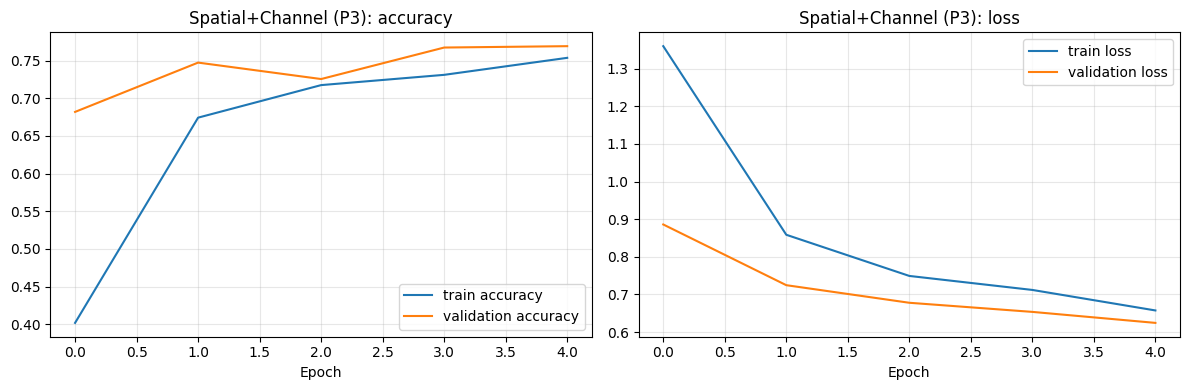

               Model Position  Accuracy  Precision   Recall       F1  Trainable Parameters  Parameters  Inference Time (ms/image)
Spatial+Channel (P3)       P3  0.749546   0.784881 0.738197 0.742786                 35975     1496071                   8.149513


In [ ]:
reverse_model, _, _ = fit_experiment("Spatial+Channel (P3)", "P3", "channel_spatial",
                                     BEST_RATIO, BEST_KERNEL, order="spatial_channel",
                                     dropout=BEST_DROPOUT, lr=BEST_LR, epochs=MAIN_EPOCHS)

Epoch 1/5
    161/Unknown 27s 130ms/step - accuracy: 0.2292 - loss: 1.6005

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


161/161 ━━━━━━━━━━━━━━━━━━━━ 32s 159ms/step - accuracy: 0.2445 - loss: 1.5859 - val_accuracy: 0.2836 - val_loss: 1.5334 - learning_rate: 0.0010
Epoch 2/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 20s 122ms/step - accuracy: 0.5516 - loss: 1.1363 - val_accuracy: 0.6855 - val_loss: 0.8148 - learning_rate: 0.0010
Epoch 3/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 20s 123ms/step - accuracy: 0.6547 - loss: 0.9054 - val_accuracy: 0.7255 - val_loss: 0.7393 - learning_rate: 0.0010
Epoch 4/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 21s 126ms/step - accuracy: 0.6742 - loss: 0.8836 - val_accuracy: 0.7418 - val_loss: 0.7303 - learning_rate: 0.0010
Epoch 5/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 21s 125ms/step - accuracy: 0.6828 - loss: 0.8521 - val_accuracy: 0.7873 - val_loss: 0.6344 - learning_rate: 0.0010


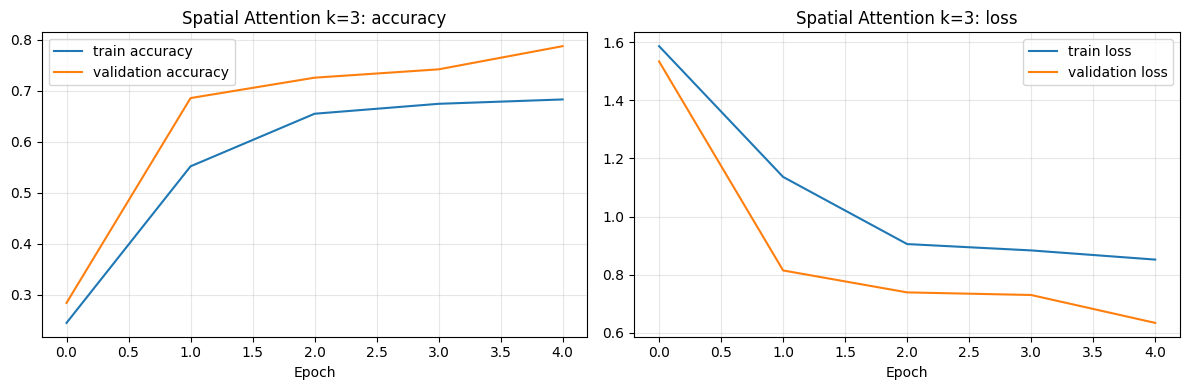

                Model Position  Accuracy  Precision   Recall       F1  Trainable Parameters  Parameters  Inference Time (ms/image)
Spatial Attention k=3       P3  0.760436   0.774348 0.760969 0.759884                  2583     1462679                   7.884765
Epoch 1/5
    161/Unknown 28s 133ms/step - accuracy: 0.2813 - loss: 1.8093

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


161/161 ━━━━━━━━━━━━━━━━━━━━ 33s 164ms/step - accuracy: 0.3406 - loss: 1.5692 - val_accuracy: 0.5982 - val_loss: 1.1467 - learning_rate: 0.0010
Epoch 2/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 22s 132ms/step - accuracy: 0.5477 - loss: 1.1580 - val_accuracy: 0.6836 - val_loss: 0.8725 - learning_rate: 0.0010
Epoch 3/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 21s 126ms/step - accuracy: 0.6139 - loss: 0.9886 - val_accuracy: 0.6782 - val_loss: 0.8322 - learning_rate: 0.0010
Epoch 4/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 21s 127ms/step - accuracy: 0.6411 - loss: 0.9346 - val_accuracy: 0.7509 - val_loss: 0.7308 - learning_rate: 0.0010
Epoch 5/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 21s 124ms/step - accuracy: 0.6785 - loss: 0.8658 - val_accuracy: 0.7473 - val_loss: 0.6749 - learning_rate: 0.0010


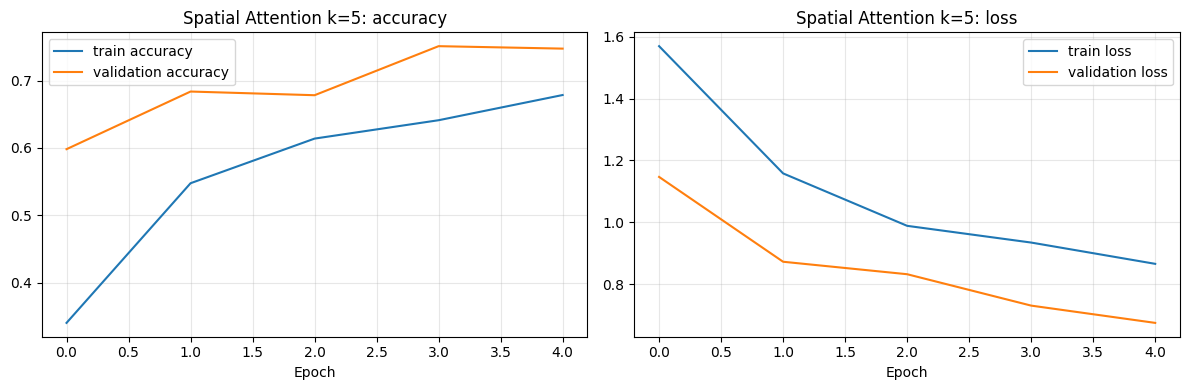

                Model Position  Accuracy  Precision   Recall       F1  Trainable Parameters  Parameters  Inference Time (ms/image)
Spatial Attention k=5       P3  0.767695   0.781431 0.761446 0.763863                  2615     1462711                   7.971058
Epoch 1/5
    161/Unknown 27s 128ms/step - accuracy: 0.2753 - loss: 1.5649

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


161/161 ━━━━━━━━━━━━━━━━━━━━ 32s 157ms/step - accuracy: 0.3620 - loss: 1.4403 - val_accuracy: 0.6655 - val_loss: 0.9325 - learning_rate: 0.0010
Epoch 2/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 20s 123ms/step - accuracy: 0.5991 - loss: 1.0304 - val_accuracy: 0.7055 - val_loss: 0.7788 - learning_rate: 0.0010
Epoch 3/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 20s 122ms/step - accuracy: 0.6434 - loss: 0.9177 - val_accuracy: 0.6800 - val_loss: 0.7980 - learning_rate: 0.0010
Epoch 4/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 20s 122ms/step - accuracy: 0.6769 - loss: 0.8538 - val_accuracy: 0.7618 - val_loss: 0.6883 - learning_rate: 3.0000e-04
Epoch 5/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 20s 122ms/step - accuracy: 0.6746 - loss: 0.8598 - val_accuracy: 0.7600 - val_loss: 0.6870 - learning_rate: 3.0000e-04


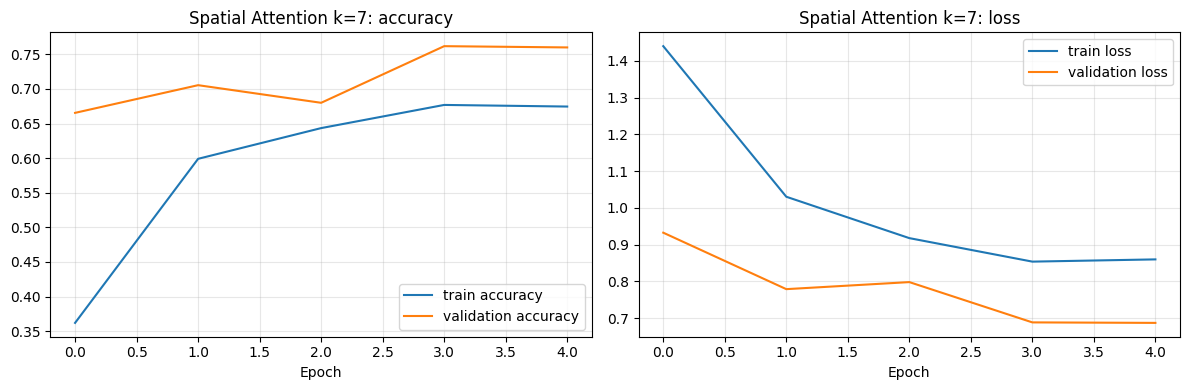

                Model Position  Accuracy  Precision   Recall       F1  Trainable Parameters  Parameters  Inference Time (ms/image)
Spatial Attention k=7       P3  0.751361   0.769181 0.743536 0.745552                  2663     1462759                    7.95732


,Spatial Kernel,Accuracy,Macro F1,Inference Time
0,3×3,0.760436,0.759884,7.884765
1,5×5,0.767695,0.763863,7.971058
2,7×7,0.751361,0.745552,7.957320


In [ ]:
kernel_rows = []
for k in [3, 5, 7]:
    name = f"Spatial Attention k={k}"
    model, hist, row = fit_experiment(name, "P3", "spatial", BEST_RATIO, k,
                                      dropout=BEST_DROPOUT, lr=BEST_LR, epochs=MAIN_EPOCHS)
    kernel_rows.append({"Spatial Kernel": f"{k}×{k}", "Accuracy": row["Accuracy"],
                        "Macro F1": row["F1"], "Inference Time": row["Inference Time (ms/image)"]})
kernel_df = pd.DataFrame(kernel_rows)
display(kernel_df)

Epoch 1/5
    161/Unknown 27s 128ms/step - accuracy: 0.3563 - loss: 1.4911

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


161/161 ━━━━━━━━━━━━━━━━━━━━ 32s 156ms/step - accuracy: 0.4807 - loss: 1.2811 - val_accuracy: 0.7345 - val_loss: 0.8419 - learning_rate: 0.0010
Epoch 2/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 20s 123ms/step - accuracy: 0.6769 - loss: 0.8613 - val_accuracy: 0.7509 - val_loss: 0.6792 - learning_rate: 0.0010
Epoch 3/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 20s 122ms/step - accuracy: 0.7112 - loss: 0.7550 - val_accuracy: 0.7345 - val_loss: 0.7056 - learning_rate: 0.0010
Epoch 4/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 20s 123ms/step - accuracy: 0.7501 - loss: 0.6801 - val_accuracy: 0.7545 - val_loss: 0.6084 - learning_rate: 3.0000e-04
Epoch 5/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 20s 122ms/step - accuracy: 0.7622 - loss: 0.6561 - val_accuracy: 0.7909 - val_loss: 0.5632 - learning_rate: 3.0000e-04


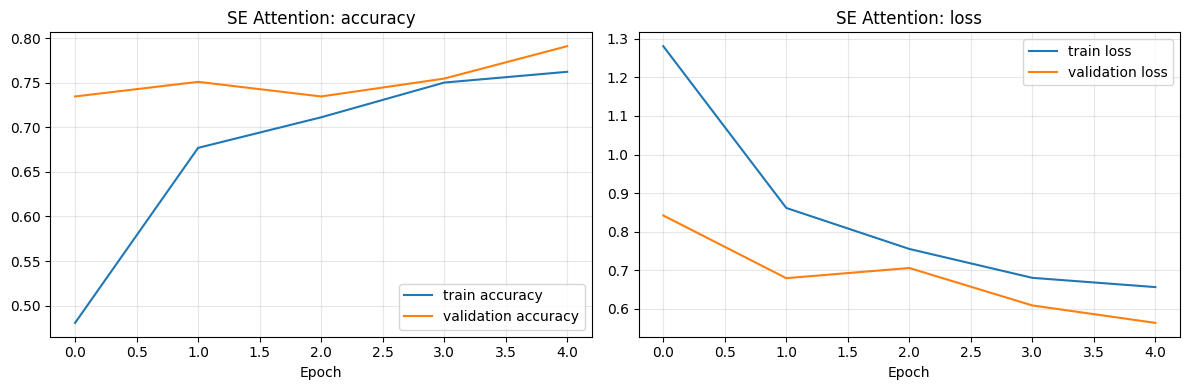

       Model Position  Accuracy  Precision   Recall       F1  Trainable Parameters  Parameters  Inference Time (ms/image)
SE Attention       P3   0.76951   0.774656 0.767545 0.766819                 35877     1495973                   7.926632
Epoch 1/5
    161/Unknown 29s 133ms/step - accuracy: 0.3307 - loss: 1.5632

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


161/161 ━━━━━━━━━━━━━━━━━━━━ 34s 163ms/step - accuracy: 0.4200 - loss: 1.3881 - val_accuracy: 0.6509 - val_loss: 1.0229 - learning_rate: 0.0010
Epoch 2/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 21s 125ms/step - accuracy: 0.6123 - loss: 1.0179 - val_accuracy: 0.7600 - val_loss: 0.7891 - learning_rate: 0.0010
Epoch 3/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 21s 127ms/step - accuracy: 0.6575 - loss: 0.9010 - val_accuracy: 0.7455 - val_loss: 0.7290 - learning_rate: 0.0010
Epoch 4/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 21s 128ms/step - accuracy: 0.7007 - loss: 0.8083 - val_accuracy: 0.7545 - val_loss: 0.6839 - learning_rate: 0.0010
Epoch 5/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 21s 129ms/step - accuracy: 0.7155 - loss: 0.7888 - val_accuracy: 0.7782 - val_loss: 0.6054 - learning_rate: 0.0010


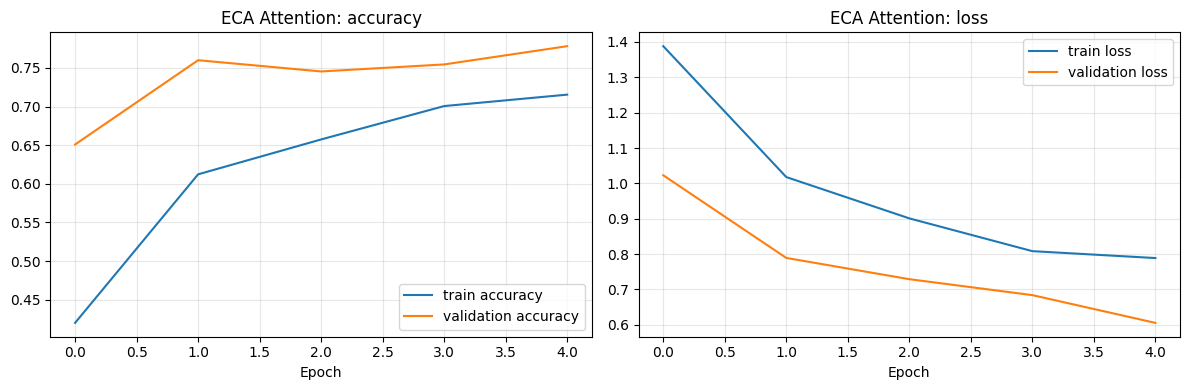

        Model Position  Accuracy  Precision   Recall       F1  Trainable Parameters  Parameters  Inference Time (ms/image)
ECA Attention       P3   0.76951   0.777113 0.763249 0.765868                  2568     1462664                   9.152203
Epoch 1/5
    161/Unknown 29s 136ms/step - accuracy: 0.3563 - loss: 1.4902

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


161/161 ━━━━━━━━━━━━━━━━━━━━ 34s 165ms/step - accuracy: 0.4800 - loss: 1.2663 - val_accuracy: 0.7091 - val_loss: 0.8703 - learning_rate: 0.0010
Epoch 2/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 21s 124ms/step - accuracy: 0.6586 - loss: 0.8861 - val_accuracy: 0.7418 - val_loss: 0.6887 - learning_rate: 0.0010
Epoch 3/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 20s 124ms/step - accuracy: 0.7077 - loss: 0.7585 - val_accuracy: 0.7545 - val_loss: 0.6219 - learning_rate: 0.0010
Epoch 4/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 20s 122ms/step - accuracy: 0.7279 - loss: 0.7174 - val_accuracy: 0.7473 - val_loss: 0.6709 - learning_rate: 0.0010
Epoch 5/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 20s 124ms/step - accuracy: 0.7591 - loss: 0.6429 - val_accuracy: 0.8000 - val_loss: 0.5511 - learning_rate: 3.0000e-04


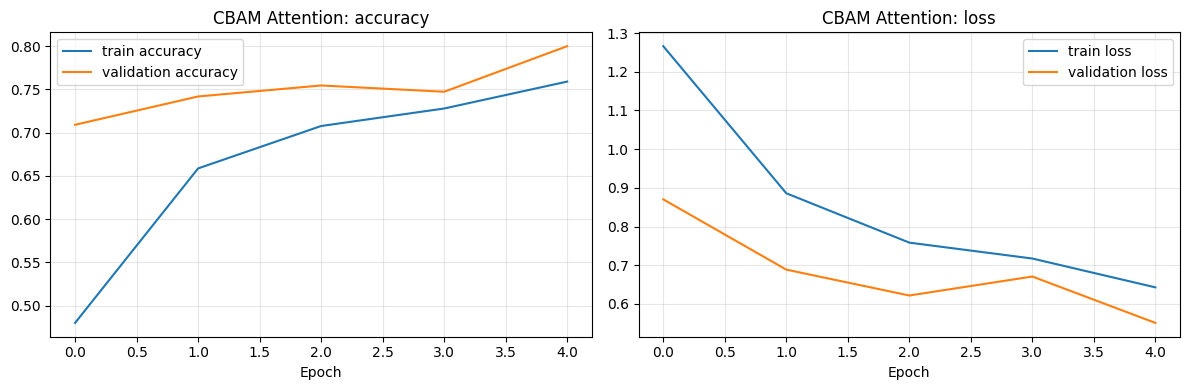

         Model Position  Accuracy  Precision   Recall       F1  Trainable Parameters  Parameters  Inference Time (ms/image)
CBAM Attention       P3  0.774955   0.779323 0.776833 0.774715                 35975     1496071                   8.045294


,Model,Position,Accuracy,Precision,Recall,F1,Trainable Parameters,Parameters,Inference Time (ms/image),Training Time (s)
0,Baseline ResNet50 (initial),–,0.733212,0.771413,0.739245,0.737666,2565,1462661,8.843187,116.907732
1,Baseline ResNet50,–,0.729583,0.753564,0.733006,0.730788,2565,1462661,7.809387,112.190814
2,Channel Attention,P3,0.760436,0.774721,0.753875,0.756732,35877,1495973,8.478753,114.501728
3,Spatial Attention,P3,0.725953,0.743452,0.729739,0.725807,2663,1462759,7.885384,116.567458
4,Channel+Spatial (P3),P3,0.742287,0.767456,0.740289,0.736844,35975,1496071,8.112818,115.237224
5,Self-Attention,P3,0.847550,0.852103,0.854814,0.848793,330886,1790982,8.503581,129.768105
6,Combined Attention,P3,0.764065,0.791161,0.771483,0.763278,35975,1496071,8.256509,116.581774
7,Channel+Spatial (P2),P2,0.577132,0.629724,0.562300,0.533742,9847,239607,4.769399,102.349621
8,Channel+Spatial (P4),P4,0.891107,0.891144,0.895472,0.890689,137383,8726567,13.447957,135.269605
9,Channel+Spatial (P3+P4),P3+P4,0.896552,0.897024,0.903404,0.897282,173353,8762537,20.303888,142.867480


In [ ]:
se_model, _, _ = fit_experiment("SE Attention", "P3", "SE", BEST_RATIO, BEST_KERNEL,
                                dropout=BEST_DROPOUT, lr=BEST_LR, epochs=MAIN_EPOCHS)
eca_model, _, _ = fit_experiment("ECA Attention", "P3", "ECA", BEST_RATIO, BEST_KERNEL,
                                 dropout=BEST_DROPOUT, lr=BEST_LR, epochs=MAIN_EPOCHS)
cbam_model, _, _ = fit_experiment("CBAM Attention", "P3", "CBAM", BEST_RATIO, BEST_KERNEL,
                                  dropout=BEST_DROPOUT, lr=BEST_LR, epochs=MAIN_EPOCHS)
display(current_results())

In [ ]:
# Keep the exact column order used in the PDF's Required Main Result Table.
required_names = [
    ("Baseline ResNet50", "Baseline", "–"),
    ("Channel Attention", "Channel Attention", "P3"),
    ("Spatial Attention", "Spatial Attention", "P3"),
    ("Channel+Spatial (P2)", "Channel+Spatial", "P2"),
    ("Channel+Spatial (P3)", "Channel+Spatial", "P3"),
    ("Channel+Spatial (P4)", "Channel+Spatial", "P4"),
    ("Self-Attention", "Self-Attention", "P3"),
    ("SE Attention", "Additional Attention-1 (SE)", "P3"),
    ("ECA Attention", "Additional Attention-2 (ECA)", "P3"),
]
lookup = {r["Model"]:r for r in result_rows}
table_rows = []
for key, label, pos in required_names:
    if key in lookup:
        r=lookup[key]
        table_rows.append({"Model":label,"Position":pos,"Accuracy":r["Accuracy"],
                           "Precision":r["Precision"],"Recall":r["Recall"],"F1":r["F1"],
                           "Parameters":r["Parameters"],"Inference Time":r["Inference Time (ms/image)"]})
required_table = pd.DataFrame(table_rows, columns=["Model","Position","Accuracy","Precision","Recall","F1","Parameters","Inference Time"])
display(required_table.style.format({"Accuracy":"{:.4f}","Precision":"{:.4f}","Recall":"{:.4f}","F1":"{:.4f}","Inference Time":"{:.3f} ms"}))

,Model,Position,Accuracy,Precision,Recall,F1,Parameters,Inference Time
0,Baseline,–,0.7296,0.7536,0.7330,0.7308,1462661,7.809 ms
1,Channel Attention,P3,0.7604,0.7747,0.7539,0.7567,1495973,8.479 ms
2,Spatial Attention,P3,0.7260,0.7435,0.7297,0.7258,1462759,7.885 ms
3,Channel+Spatial,P2,0.5771,0.6297,0.5623,0.5337,239607,4.769 ms
4,Channel+Spatial,P3,0.7423,0.7675,0.7403,0.7368,1496071,8.113 ms
5,Channel+Spatial,P4,0.8911,0.8911,0.8955,0.8907,8726567,13.448 ms
6,Self-Attention,P3,0.8475,0.8521,0.8548,0.8488,1790982,8.504 ms
7,Additional Attention-1 (SE),P3,0.7695,0.7747,0.7675,0.7668,1495973,7.927 ms
8,Additional Attention-2 (ECA),P3,0.7695,0.7771,0.7632,0.7659,1462664,9.152 ms


In [ ]:
comparison_rows=[]
for r in result_rows:
    if r["Model"] in ["Baseline ResNet50","Channel Attention","Spatial Attention","SE Attention","ECA Attention","CBAM Attention","Self-Attention"]:
        comparison_rows.append({"Attention":r["Model"],"Accuracy":r["Accuracy"],"Precision":r["Precision"],
                                "Recall":r["Recall"],"Macro F1":r["F1"],"Parameters":r["Parameters"],
                                "Inference Time":r["Inference Time (ms/image)"]})
attention_comparison = pd.DataFrame(comparison_rows)
display(attention_comparison.style.format({"Accuracy":"{:.4f}","Precision":"{:.4f}","Recall":"{:.4f}","Macro F1":"{:.4f}","Inference Time":"{:.3f} ms"}))

,Attention,Accuracy,Precision,Recall,Macro F1,Parameters,Inference Time
0,Baseline ResNet50,0.7296,0.7536,0.7330,0.7308,1462661,7.809 ms
1,Channel Attention,0.7604,0.7747,0.7539,0.7567,1495973,8.479 ms
2,Spatial Attention,0.7260,0.7435,0.7297,0.7258,1462759,7.885 ms
3,Self-Attention,0.8475,0.8521,0.8548,0.8488,1790982,8.504 ms
4,SE Attention,0.7695,0.7747,0.7675,0.7668,1495973,7.927 ms
5,ECA Attention,0.7695,0.7771,0.7632,0.7659,1462664,9.152 ms
6,CBAM Attention,0.7750,0.7793,0.7768,0.7747,1496071,8.045 ms


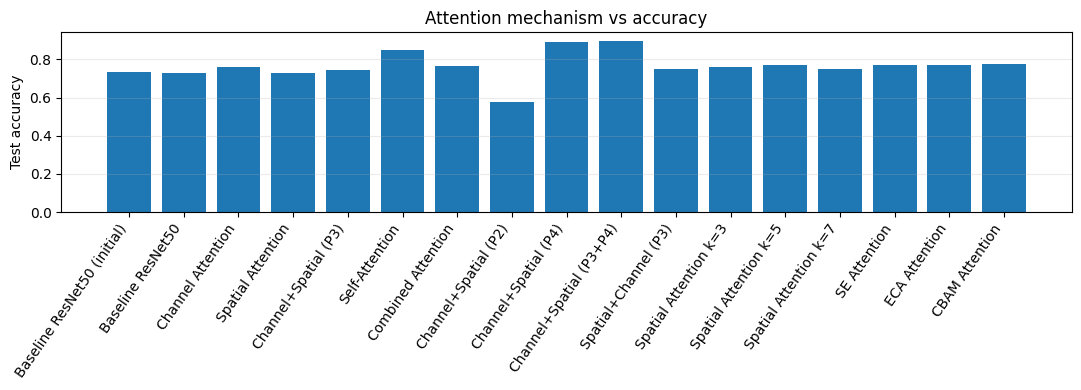

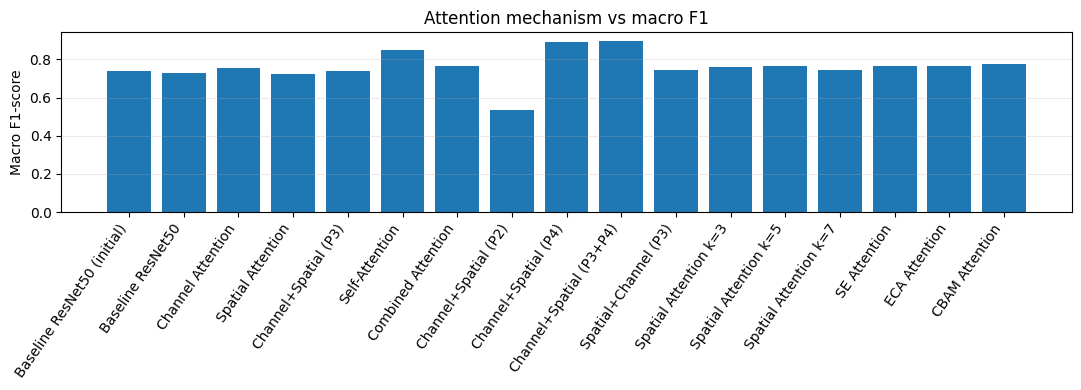

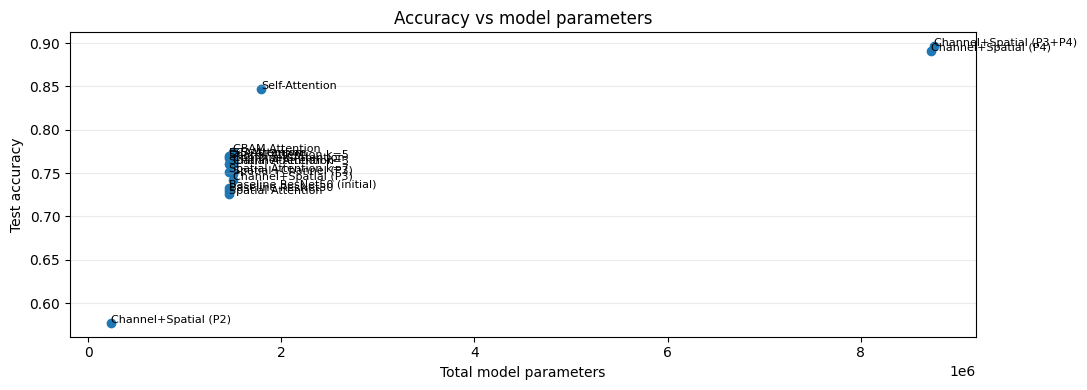

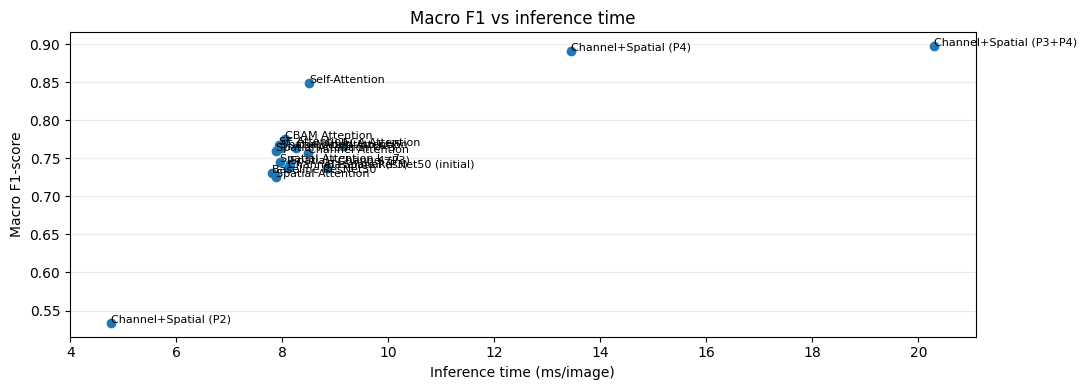

In [ ]:
plot_df = current_results()
metric_models = plot_df["Model"].tolist()
for metric, title, ylabel in [
    ("Accuracy","Attention mechanism vs accuracy","Test accuracy"),
    ("F1","Attention mechanism vs macro F1","Macro F1-score"),
    ("Parameters","Accuracy vs model parameters","Total parameters"),
    ("Inference Time (ms/image)","Macro F1 vs inference time","Inference time (ms/image)")
]:
    plt.figure(figsize=(11,4))
    if metric == "Parameters":
        plt.scatter(plot_df["Parameters"], plot_df["Accuracy"])
        for _,r in plot_df.iterrows():
            plt.annotate(r["Model"], (r["Parameters"],r["Accuracy"]), fontsize=8)
        plt.xlabel("Total model parameters"); plt.ylabel("Test accuracy")
        plt.title(title)
    elif metric == "Inference Time (ms/image)":
        plt.scatter(plot_df[metric], plot_df["F1"])
        for _,r in plot_df.iterrows():
            plt.annotate(r["Model"], (r[metric],r["F1"]), fontsize=8)
        plt.xlabel("Inference time (ms/image)"); plt.ylabel("Macro F1-score")
        plt.title(title)
    else:
        plt.bar(metric_models, plot_df[metric])
        plt.ylabel(ylabel); plt.title(title); plt.xticks(rotation=55, ha="right")
    plt.grid(axis="y", alpha=.25); plt.tight_layout(); plt.show()

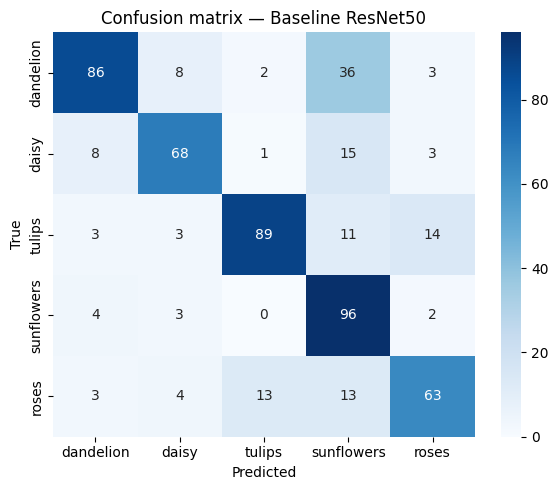

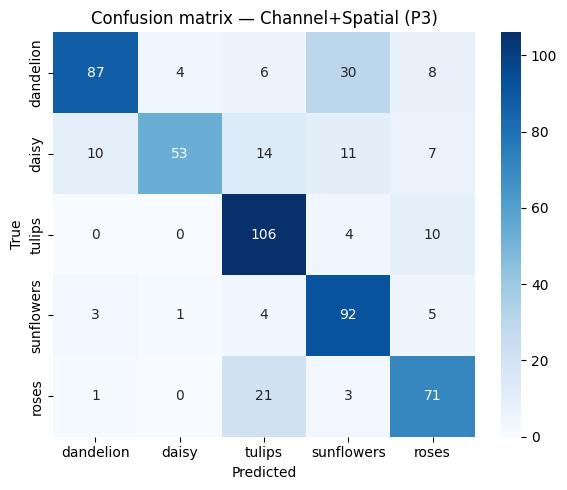

In [ ]:
def show_confusion(model_name):
    r = next(r for r in result_rows if r["Model"] == model_name)
    cm = confusion_matrix(r["y_true"], r["y_pred"], labels=np.arange(num_classes))
    plt.figure(figsize=(6,5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names)
    plt.xlabel("Predicted"); plt.ylabel("True"); plt.title(f"Confusion matrix — {model_name}")
    plt.tight_layout(); plt.show()
show_confusion("Baseline ResNet50")
show_confusion("Channel+Spatial (P3)")

In [ ]:
selected_name = "Channel+Spatial (P3)"
selected_row = next(r for r in result_rows if r["Model"] == selected_name)
print(classification_report(selected_row["y_true"], selected_row["y_pred"], target_names=class_names, zero_division=0))

              precision    recall  f1-score   support

   dandelion       0.86      0.64      0.74       135
       daisy       0.91      0.56      0.69        95
      tulips       0.70      0.88      0.78       120
  sunflowers       0.66      0.88      0.75       105
       roses       0.70      0.74      0.72        96

    accuracy                           0.74       551
   macro avg       0.77      0.74      0.74       551
weighted avg       0.77      0.74      0.74       551



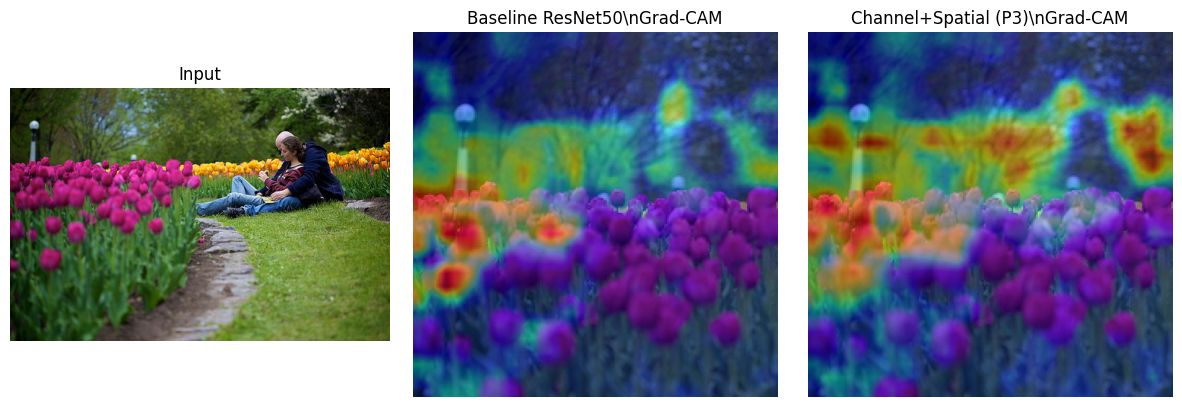

In [ ]:
def make_gradcam_heatmap(img_tensor, model_name, pred_index=None):
    # True gradient-based CAM: gradients of the predicted class score w.r.t. the selected stage feature tensor.
    model = model_store[model_name]
    head = head_store[model_name]
    position = next(r["Position"] for r in result_rows if r["Model"] == model_name)
    if position not in stage_models:
        position = "P3"
    extractor = stage_models[position]
    with tf.GradientTape() as tape:
        features = extractor(img_tensor, training=False)
        tape.watch(features)
        predictions = head(features, training=False)
        class_idx = tf.argmax(predictions[0]) if pred_index is None else pred_index
        score = predictions[:, class_idx]
    grads = tape.gradient(score, features)
    weights = tf.reduce_mean(grads, axis=(1, 2), keepdims=True)
    cam = tf.nn.relu(tf.reduce_sum(weights * features, axis=-1))
    cam = cam / (tf.reduce_max(cam, axis=(1, 2), keepdims=True) + 1e-8)
    return cam[0].numpy()

def display_gradcam_pair(sample_index=None):
    if sample_index is None:
        sample_index = int(test_idx[0])
    raw = images[sample_index]
    x = tf.image.resize(tf.cast(raw, tf.float32), IMG_SIZE)
    inp = tf.keras.applications.resnet50.preprocess_input(x)[None, ...]
    fig, ax = plt.subplots(1, 3, figsize=(12, 4))
    ax[0].imshow(raw); ax[0].set_title("Input"); ax[0].axis("off")
    for a, name in zip(ax[1:], ["Baseline ResNet50", "Channel+Spatial (P3)"]):
        heat = make_gradcam_heatmap(inp, name)
        heat = tf.image.resize(heat[..., None], IMG_SIZE).numpy().squeeze()
        a.imshow(raw); a.imshow(heat, cmap="jet", alpha=0.45)
        a.set_title(name + "\\nGrad-CAM"); a.axis("off")
    plt.tight_layout(); plt.show()

display_gradcam_pair()

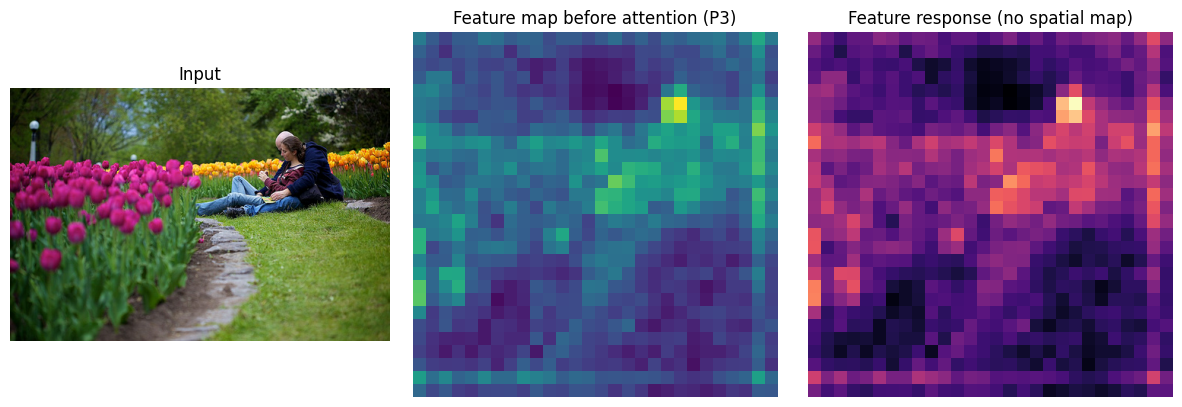

In [ ]:
def visualize_attention_map(sample_index, model_name):
    row = next(r for r in result_rows if r["Model"] == model_name)
    model = model_store[model_name]
    pos = row["Position"] if row["Position"] in stage_models else "P3"
    raw = images[sample_index]
    x = tf.image.resize(tf.cast(raw,tf.float32), IMG_SIZE)
    inp = tf.keras.applications.resnet50.preprocess_input(x)[None,...]
    feature = stage_models[pos](inp, training=False)
    maps = attention_tensors.get(model_name)
    fig, axes = plt.subplots(1,3,figsize=(12,4))
    axes[0].imshow(raw); axes[0].set_title("Input"); axes[0].axis("off")
    axes[1].imshow(np.mean(feature.numpy()[0],axis=-1), cmap="viridis")
    axes[1].set_title(f"Feature map before attention ({pos})"); axes[1].axis("off")
    # Internal map: build a map-only model from the same feature input for spatial/channel modules.
    # The trained model's attention weights can be visualized using the stored attention layer outputs where available.
    try:
        attn_layer = next((l for l in model.layers if "spatial" in l.name and ("conv" in l.name or "sigmoid" in l.name)), None)
        if attn_layer is not None:
            axes[2].text(.5,.5,"Spatial attention layer found\n(run model.summary() to inspect)",ha="center",va="center")
            axes[2].axis("off")
        else:
            axes[2].imshow(np.mean(feature.numpy()[0],axis=-1), cmap="magma")
            axes[2].set_title("Feature response (no spatial map)"); axes[2].axis("off")
    except Exception as e:
        axes[2].text(.5,.5,str(e),ha="center",va="center"); axes[2].axis("off")
    plt.tight_layout(); plt.show()

visualize_attention_map(int(test_idx[0]), "Channel+Spatial (P3)")

In [ ]:
os.makedirs("attention_experiment_outputs", exist_ok=True)
current_results().to_csv("attention_experiment_outputs/all_experiment_results.csv", index=False)
required_table.to_csv("attention_experiment_outputs/required_main_result_table.csv", index=False)
attention_comparison.to_csv("attention_experiment_outputs/attention_mechanism_comparison.csv", index=False)
kernel_df.to_csv("attention_experiment_outputs/spatial_kernel_comparison.csv", index=False)
tuning_df.to_csv("attention_experiment_outputs/hyperparameter_tuning.csv", index=False)
for name, hist in history_store.items():
    pd.DataFrame(hist.history).to_csv(
        os.path.join("attention_experiment_outputs", name.replace("/","_").replace(" ","_") + "_history.csv"),
        index=False
    )
print("Saved outputs to ./attention_experiment_outputs/")
print("Final result table:")
display(required_table)

Saved outputs to ./attention_experiment_outputs/
Final result table:


,Model,Position,Accuracy,Precision,Recall,F1,Parameters,Inference Time
0,Baseline,–,0.729583,0.753564,0.733006,0.730788,1462661,7.809387
1,Channel Attention,P3,0.760436,0.774721,0.753875,0.756732,1495973,8.478753
2,Spatial Attention,P3,0.725953,0.743452,0.729739,0.725807,1462759,7.885384
3,Channel+Spatial,P2,0.577132,0.629724,0.562300,0.533742,239607,4.769399
4,Channel+Spatial,P3,0.742287,0.767456,0.740289,0.736844,1496071,8.112818
5,Channel+Spatial,P4,0.891107,0.891144,0.895472,0.890689,8726567,13.447957
6,Self-Attention,P3,0.847550,0.852103,0.854814,0.848793,1790982,8.503581
7,Additional Attention-1 (SE),P3,0.769510,0.774656,0.767545,0.766819,1495973,7.926632
8,Additional Attention-2 (ECA),P3,0.769510,0.777113,0.763249,0.765868,1462664,9.152203
